In [ ]:
# ── Cell 1: install ──────────────────────────────────────────
!pip install -q open_clip_torch roboflow scikit-learn matplotlib pillow
# (the inference package takes ~2 min to install)

In [ ]:
# ── Cell 2: get your images ──────────────────────────────────
# Option A — pull your dataset from Roboflow
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="0zfMWbCXHoFqNZuWNTPG")
project = rf.workspace("plan-usinage").project("watch-model-gcbay")
version = project.version(1)
dataset = version.download("folder")
IMAGE_DIR = dataset.location
print("images in:", IMAGE_DIR)


loading Roboflow workspace...
loading Roboflow project...
images in: /content/watch-model-1


In [ ]:
# ── Cell 3: collect image paths ──────────────────────────────
import glob, os
paths = [p for ext in ("jpg","jpeg","png","webp")
         for p in glob.glob(os.path.join(IMAGE_DIR, "**", f"*.{ext}"), recursive=True)]
print(f"Found {len(paths)} images")

Found 1904 images


In [ ]:
# ── Cell 4: CLIP embeddings (via Roboflow Inference) ─────────
import open_clip, torch, numpy as np
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k")
model = model.to(device).eval()

emb = []
with torch.no_grad():
    for i, p in enumerate(paths):
        img = preprocess(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
        emb.append(model.encode_image(img)[0].cpu().numpy())
        if (i+1) % 50 == 0: print(f"embedded {i+1}/{len(paths)}")
emb = np.array(emb)
print("embeddings:", emb.shape)


The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.


open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

embedded 50/1904
embedded 100/1904
embedded 150/1904
embedded 200/1904
embedded 250/1904
embedded 300/1904
embedded 350/1904
embedded 400/1904
embedded 450/1904
embedded 500/1904
embedded 550/1904
embedded 600/1904
embedded 650/1904
embedded 700/1904
embedded 750/1904
embedded 800/1904
embedded 850/1904
embedded 900/1904
embedded 950/1904
embedded 1000/1904
embedded 1050/1904
embedded 1100/1904
embedded 1150/1904
embedded 1200/1904
embedded 1250/1904
embedded 1300/1904
embedded 1350/1904
embedded 1400/1904
embedded 1450/1904
embedded 1500/1904
embedded 1550/1904
embedded 1600/1904
embedded 1650/1904
embedded 1700/1904
embedded 1750/1904
embedded 1800/1904
embedded 1850/1904
embedded 1900/1904
embeddings: (1904, 512)


In [ ]:
# ── Cell 5: cluster with K-means ─────────────────────────────
# ── Cell 5 (improved) ────────────────────────────────────────
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# normalize so distance ≈ cosine, then squash 512 dims -> 50 to denoise
X = normalize(emb)
X = PCA(n_components=50, random_state=42).fit_transform(X)

# let the data tell you a good K
for k in range(4, 16):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    print(f"K={k:2d}  silhouette={silhouette_score(X, lab):.3f}")



K= 4  silhouette=0.094
K= 5  silhouette=0.099
K= 6  silhouette=0.096
K= 7  silhouette=0.101
K= 8  silhouette=0.105
K= 9  silhouette=0.106
K=10  silhouette=0.096
K=11  silhouette=0.092
K=12  silhouette=0.096
K=13  silhouette=0.092
K=14  silhouette=0.090
K=15  silhouette=0.093


In [ ]:
K = 15  # ← set to the best from the sweep
labels = KMeans(n_clusters=K, random_state=42, n_init=10).fit_predict(X)

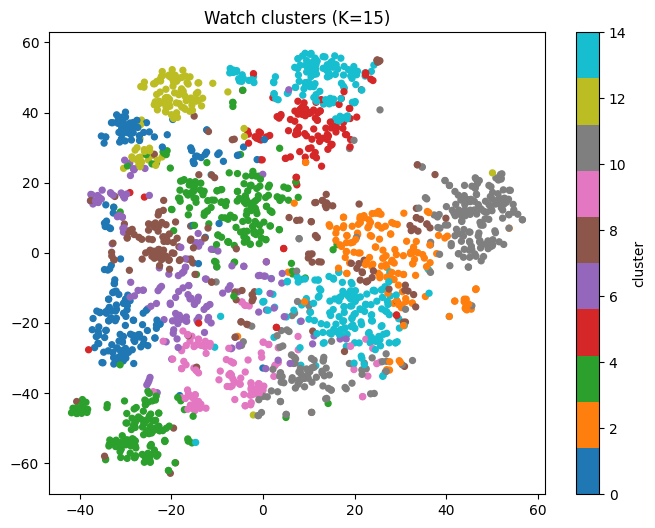

In [ ]:
# ── Cell 6: 2-D map of the clusters ──────────────────────────
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
xy = TSNE(n_components=2, random_state=42, init="pca",
          perplexity=min(30, len(paths)-1)).fit_transform(emb)
plt.figure(figsize=(8,6))
plt.scatter(xy[:,0], xy[:,1], c=labels, cmap="tab10", s=18)
plt.title(f"Watch clusters (K={K})"); plt.colorbar(label="cluster"); plt.show()

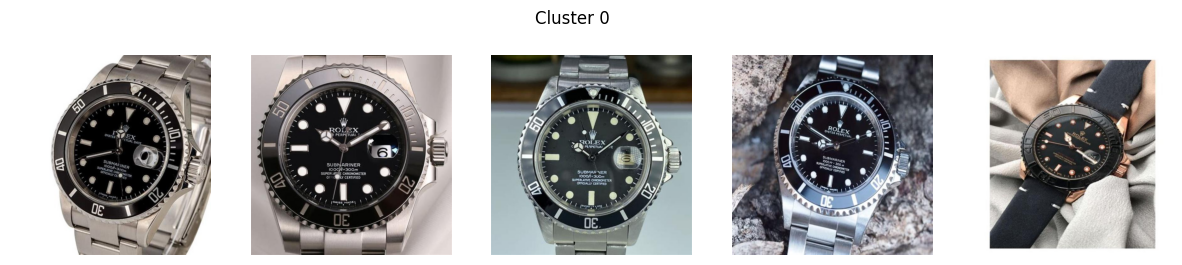

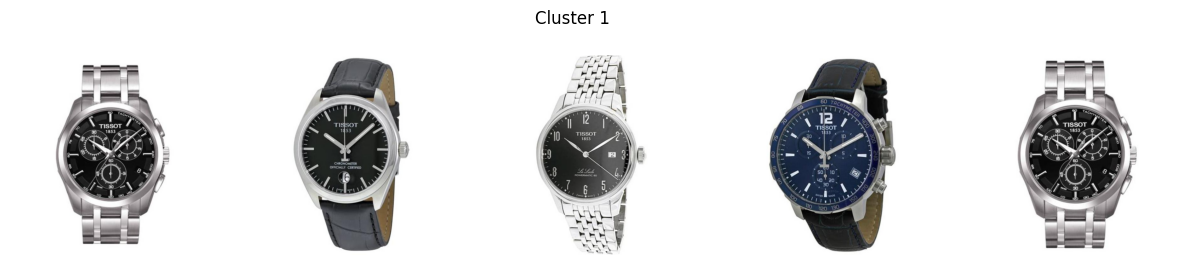

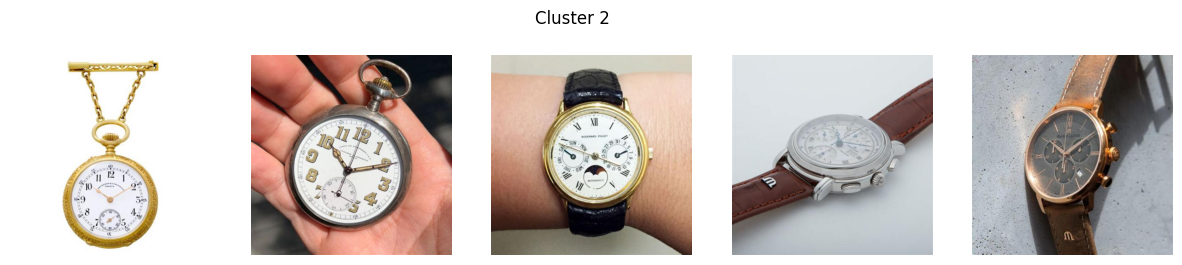

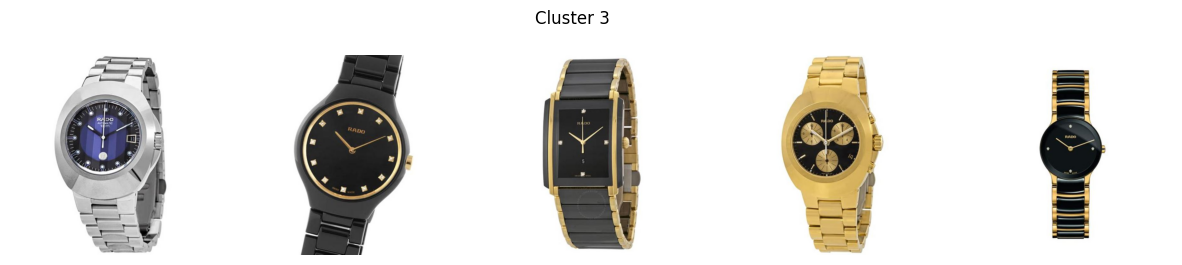

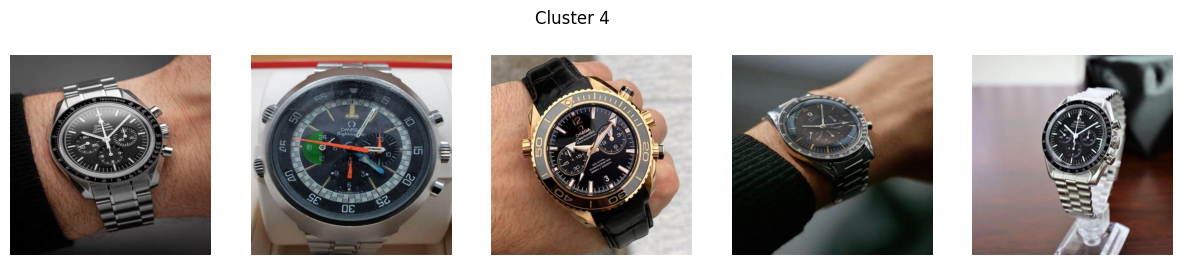

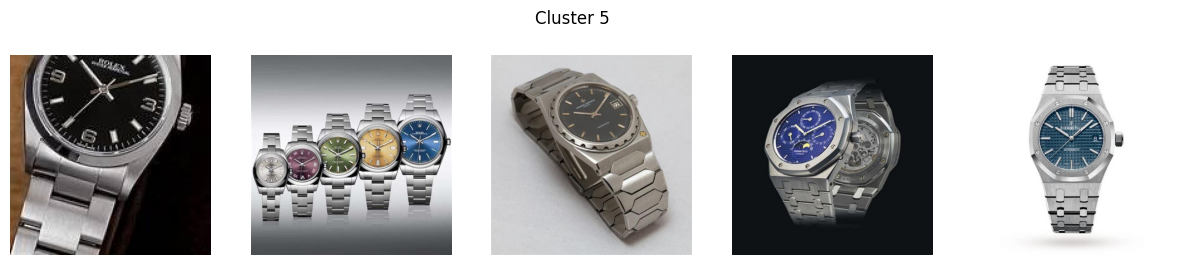

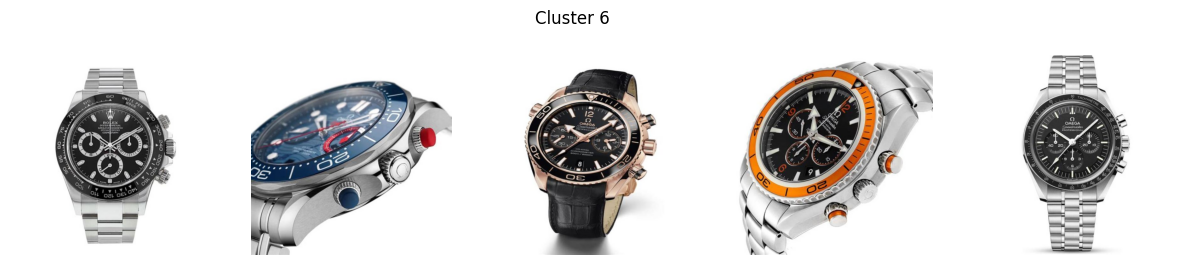

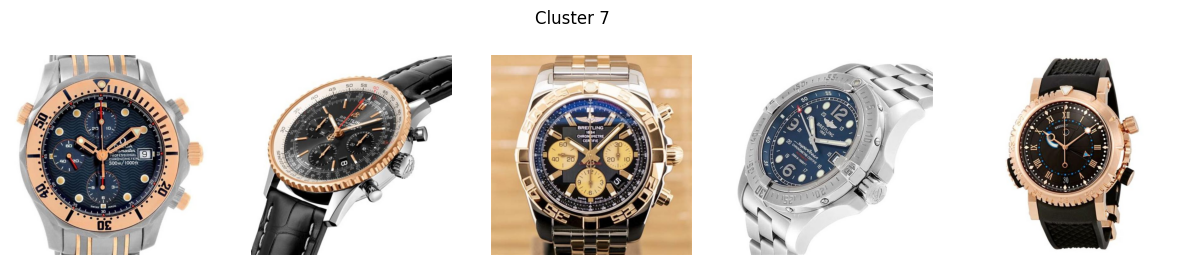

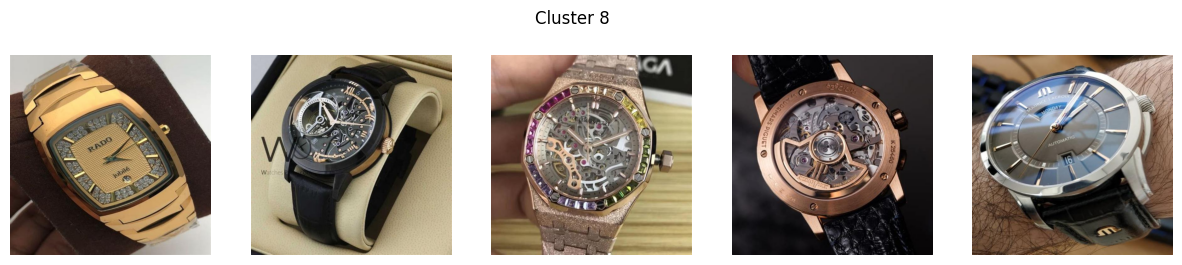

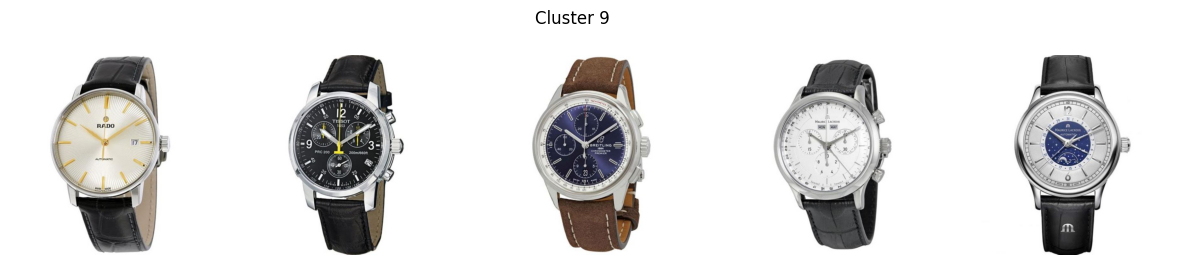

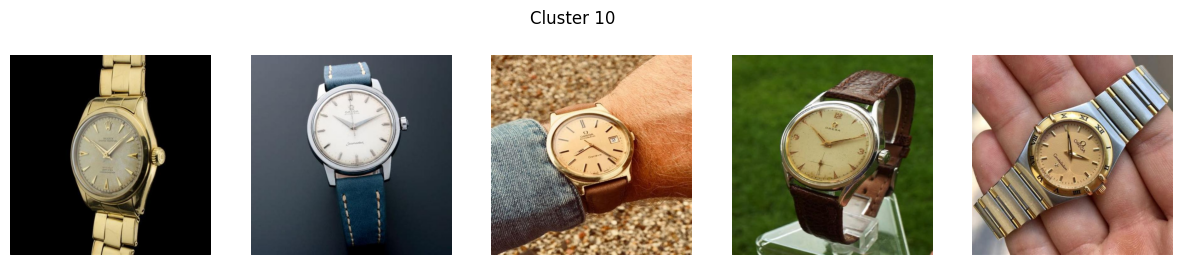

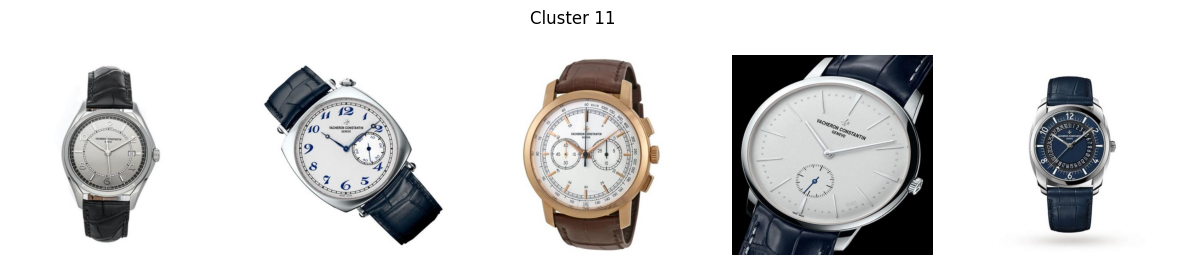

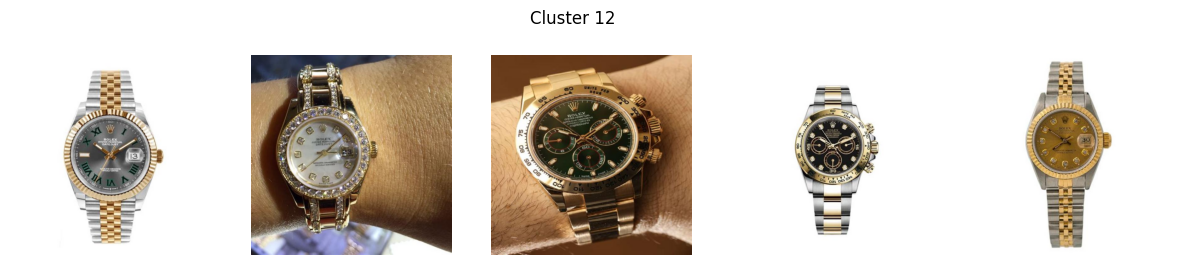

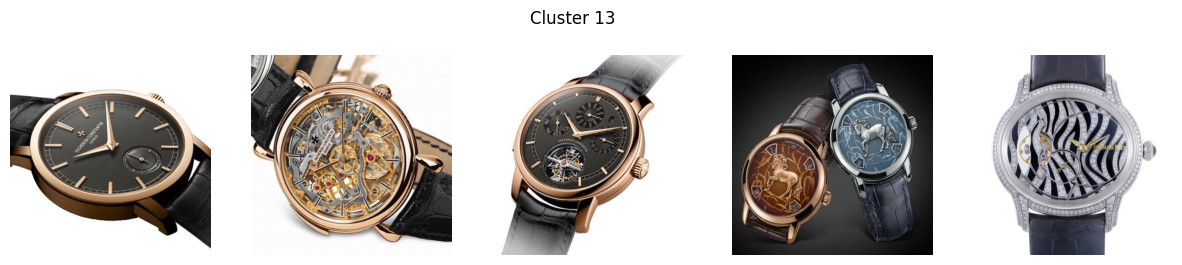

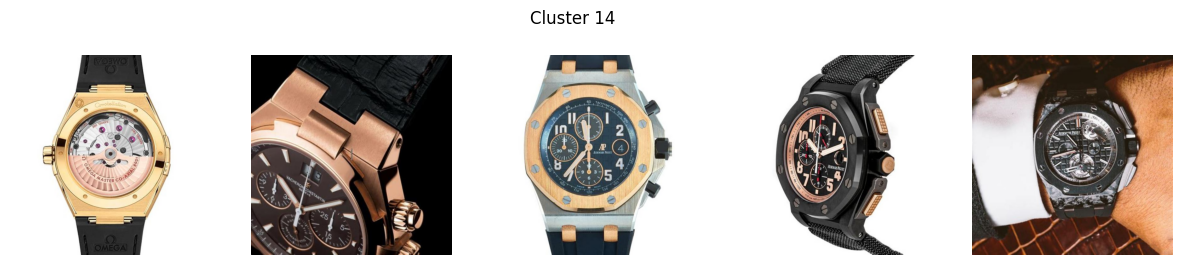

In [ ]:
# ── Cell 7: peek at what each cluster grabbed ────────────────
from PIL import Image
for c in range(K):
    members = [p for p, l in zip(paths, labels) if l == c][:5]
    if not members: continue
    fig, axes = plt.subplots(1, len(members), figsize=(3*len(members), 3))
    if len(members) == 1: axes = [axes]
    for ax, mp in zip(axes, members):
        ax.imshow(Image.open(mp).convert("RGB")); ax.axis("off")
    fig.suptitle(f"Cluster {c}"); plt.show()